# Projeto 1 — Inteligência Artificial: Distribuição de Alimentos Locais

## 1. Introdução

Este projeto, desenvolvido no âmbito da unidade curricular de Inteligência Artificial, tem como objetivo criar um agente inteligente capaz de planear e otimizar rotas de recolha e distribuição de produtos alimentares locais.

O sistema considera produtores, clientes, centros de recolha e veículos, procurando encontrar rotas eficientes que respeitem restrições como os horários de disponibilidade dos produtos, os prazos de entrega e a capacidade dos veículos.

Nesta primeira fase, será realizada uma Análise Exploratória dos Dados (EDA), com o objetivo de compreender a estrutura do dataset, verificar a qualidade e consistência dos dados e identificar as informações necessárias para a posterior implementação dos algoritmos de Inteligência Artificial.

In [ ]:
import pandas as pd
import zipfile
from google.colab import files

# Selecionar o ficheiro data_tiny.zip
uploaded = files.upload()

# Extrair o dataset
with zipfile.ZipFile("data_tiny.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset extraído com sucesso!")

Saving data_tiny.zip to data_tiny.zip
Dataset extraído com sucesso!


## 2. Análise Exploratória dos Dados (EDA)

### 2.1. Carregamento do Dataset

Nesta etapa, são carregados os ficheiros CSV disponibilizados para o projeto. O objetivo é identificar as diferentes entidades presentes no dataset e compreender a quantidade e a estrutura dos dados disponíveis.

In [ ]:

import pandas as pd
from pathlib import Path

# Ficheiros necessários ao projeto
nomes_ficheiros = [
    "collection_centers", "customers",
    "delivery_locations", "distance_matrix",
    "localities", "locations", "order_items",
    "orders", "producers", "products", "vehicles"
]

# Procurar os CSV nas pastas extraídas
dados = {}

for nome in nomes_ficheiros:
    ficheiros = list(Path(".").rglob(f"{nome}.csv"))

    if not ficheiros:
        print(f"Ficheiro não encontrado: {nome}.csv")
        continue

    dados[nome] = pd.read_csv(ficheiros[0])

# Mostrar os resultados
print("\nFicheiros do projeto carregados:\n")

for nome, tabela in dados.items():
    print(f"{nome}: {len(tabela)} registos")



Ficheiros do projeto carregados:

collection_centers: 1 registos
customers: 8 registos
delivery_locations: 6 registos
distance_matrix: 132 registos
localities: 49 registos
locations: 12 registos
order_items: 23 registos
orders: 10 registos
producers: 5 registos
products: 23 registos
vehicles: 2 registos


In [ ]:

# Mostrar a tabela dos produtores
display(dados["producers"])


,producer_id,name,locality_id,address,phone,email
0,1,Hortas Valente,23,"Largo Amaral, S/N",(351) 928 063 608,veramatos@oliveira.net
1,2,Quinta Leite,39,"Praça Nuno Alves, 28",(351) 924 158 683,noa97@pinho.com
2,3,Quinta Morais,12,"Alameda do Ouro, 6",+351961781286,debora07@goncalves.com
3,4,Pomar Carvalho,49,"Rua Nunes, 73",935957489,macedoyasmin@neto.pt
4,5,Pomar Antunes,23,"Rua de Moura, 67",925 088 995,bpinto@rocha.com


### 2.2. Análise dos Produtores

Nesta secção, são analisados os produtores presentes no dataset, com o objetivo de identificar a sua estrutura, os atributos disponíveis e as informações relevantes para o planeamento das rotas de recolha de produtos.

In [ ]:

# Visualizar os produtores
display(dados["producers"])

# Verificar a estrutura da tabela
print("\nInformações sobre os produtores:")
dados["producers"].info()

# Verificar valores em falta
print("\nValores em falta:")
print(dados["producers"].isnull().sum())


,producer_id,name,locality_id,address,phone,email
0,1,Hortas Valente,23,"Largo Amaral, S/N",(351) 928 063 608,veramatos@oliveira.net
1,2,Quinta Leite,39,"Praça Nuno Alves, 28",(351) 924 158 683,noa97@pinho.com
2,3,Quinta Morais,12,"Alameda do Ouro, 6",+351961781286,debora07@goncalves.com
3,4,Pomar Carvalho,49,"Rua Nunes, 73",935957489,macedoyasmin@neto.pt
4,5,Pomar Antunes,23,"Rua de Moura, 67",925 088 995,bpinto@rocha.com



Informações sobre os produtores:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   producer_id  5 non-null      int64 
 1   name         5 non-null      object
 2   locality_id  5 non-null      int64 
 3   address      5 non-null      object
 4   phone        5 non-null      object
 5   email        5 non-null      object
dtypes: int64(2), object(4)
memory usage: 372.0+ bytes

Valores em falta:
producer_id    0
name           0
locality_id    0
address        0
phone          0
email          0
dtype: int64


### 2.2.1. Resultados da Análise dos Produtores

A análise do ficheiro `producers.csv` permitiu identificar 5 produtores, distribuídos por 6 atributos: `producer_id`, `name`, `locality_id`, `address`, `phone` e `email`.

Não foram identificados valores em falta em nenhuma das colunas, o que indica que os registos estão completos relativamente aos atributos analisados.

O atributo `producer_id` identifica cada produtor, enquanto `locality_id` permite estabelecer uma relação com a tabela de localidades, sendo relevante para determinar a localização geográfica dos produtores.

Estes dados serão utilizados nas fases seguintes do projeto para identificar os pontos de recolha dos produtos e apoiar o planeamento das rotas de distribuição.

### 2.3. Análise dos Veículos

Nesta secção, são analisados os veículos disponíveis para o transporte dos produtos. O objetivo é identificar as características de cada veículo, nomeadamente a sua capacidade de carga, uma vez que esta constitui uma restrição importante no planeamento das rotas.

In [ ]:

# Visualizar os veículos
display(dados["vehicles"])

# Verificar a estrutura da tabela
print("\nInformações sobre os veículos:")
dados["vehicles"].info()

# Verificar valores em falta
print("\nValores em falta:")
print(dados["vehicles"].isnull().sum())


,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,1444.7,0,57.8
1,2,TY-74-YA,1,1009.8,0,59.5



Informações sobre os veículos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   vehicle_id     2 non-null      int64  
 1   plate          2 non-null      object 
 2   center_id      2 non-null      int64  
 3   capacity_kg    2 non-null      float64
 4   refrigerated   2 non-null      int64  
 5   avg_speed_kmh  2 non-null      float64
dtypes: float64(2), int64(3), object(1)
memory usage: 228.0+ bytes

Valores em falta:
vehicle_id       0
plate            0
center_id        0
capacity_kg      0
refrigerated     0
avg_speed_kmh    0
dtype: int64


### 2.3.1. Resultados da Análise dos Veículos

A análise do ficheiro `vehicles.csv` permitiu identificar 2 veículos disponíveis para o transporte e distribuição dos produtos alimentares.

O primeiro veículo, com matrícula ZG-06-DP, apresenta uma capacidade máxima de 1444,7 kg e uma velocidade média de 57,8 km/h. O segundo veículo, com matrícula TY-74-YA, apresenta uma capacidade máxima de 1009,8 kg e uma velocidade média de 59,5 km/h.

Ambos os veículos pertencem ao centro de recolha identificado por `center_id = 1` e não possuem sistema de refrigeração, uma vez que o atributo `refrigerated` apresenta o valor 0.

Não foram identificados valores em falta nos registos analisados.

A capacidade de carga constitui uma restrição fundamental para o planeamento das rotas, uma vez que o peso transportado em cada momento não poderá ultrapassar o limite do veículo. As velocidades médias poderão também ser consideradas na análise dos tempos de deslocação.


### 2.4. Análise das Encomendas

Nesta secção, são analisadas as encomendas realizadas pelos clientes e os respetivos artigos. O objetivo é identificar a estrutura dos pedidos, as quantidades de produtos solicitadas e as informações necessárias para planear as operações de recolha e entrega.

In [ ]:

# Visualizar as encomendas
print("Tabela de encomendas:")
display(dados["orders"])

# Visualizar os artigos de cada encomenda
print("\nArtigos das encomendas:")
display(dados["order_items"])

# Verificar a estrutura dos dados
print("\nInformações sobre as encomendas:")
dados["orders"].info()

print("\nInformações sobre os artigos:")
dados["order_items"].info()

# Verificar valores em falta
print("\nValores em falta nas encomendas:")
print(dados["orders"].isnull().sum())

print("\nValores em falta nos artigos:")
print(dados["order_items"].isnull().sum())


Tabela de encomendas:


,order_id,customer_id,delivery_location_id,order_datetime,status
0,1,5,6,2026-10-15 10:45:00,placed
1,2,6,6,2026-10-17 13:00:00,confirmed
2,3,1,4,2026-10-10 12:00:00,placed
3,4,3,2,2026-10-15 10:30:00,confirmed
4,5,4,5,2026-10-08 11:30:00,confirmed
5,6,2,1,2026-10-10 10:45:00,placed
6,7,7,5,2026-10-20 11:30:00,delivered
7,8,4,3,2026-10-10 10:30:00,placed
8,9,5,5,2026-10-20 08:00:00,placed
9,10,3,2,2026-10-19 09:15:00,confirmed



Artigos das encomendas:


,order_item_id,order_id,product_id,quantity,availability_start,availability_end,delivery_start,delivery_end
0,1,1,1,14.1,2026-10-13 08:00:00,2026-10-13 11:00:00,2026-10-13 13:00:00,2026-10-13 17:00:00
1,2,1,8,17.2,2026-10-17 12:45:00,2026-10-17 15:45:00,2026-10-18 13:45:00,2026-10-18 17:45:00
2,3,2,7,11.0,2026-10-07 09:00:00,2026-10-07 11:00:00,2026-10-07 12:00:00,2026-10-07 14:00:00
3,4,2,9,5.1,2026-10-09 07:00:00,2026-10-09 13:00:00,2026-10-09 12:00:00,2026-10-09 16:00:00
4,5,3,19,1.4,2026-10-10 10:00:00,2026-10-10 15:00:00,2026-10-10 15:00:00,2026-10-10 19:00:00
5,6,3,20,20.5,2026-10-20 10:30:00,2026-10-20 12:30:00,2026-10-20 12:30:00,2026-10-20 15:30:00
6,7,3,19,21.1,2026-10-19 08:30:00,2026-10-19 13:30:00,2026-10-19 11:30:00,2026-10-19 12:30:00
7,8,3,18,3.0,2026-10-12 12:45:00,2026-10-12 18:45:00,2026-10-12 13:45:00,2026-10-12 14:45:00
8,9,4,12,4.2,2026-10-12 09:00:00,2026-10-12 13:00:00,2026-10-12 14:00:00,2026-10-12 18:00:00
9,10,4,18,21.8,2026-10-19 07:30:00,2026-10-19 09:30:00,2026-10-19 08:30:00,2026-10-19 12:30:00



Informações sobre as encomendas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   order_id              10 non-null     int64 
 1   customer_id           10 non-null     int64 
 2   delivery_location_id  10 non-null     int64 
 3   order_datetime        10 non-null     object
 4   status                10 non-null     object
dtypes: int64(3), object(2)
memory usage: 532.0+ bytes

Informações sobre os artigos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_item_id       23 non-null     int64  
 1   order_id            23 non-null     int64  
 2   product_id          23 non-null     int64  
 3   quantity            23 non-null     float64
 4   availability_start  23 non-n

### 2.4.1. Resultados da Análise das Encomendas

A análise do dataset permitiu identificar 10 encomendas e 23 artigos associados a essas encomendas.

A tabela `orders.csv` contém informações sobre os clientes, os locais de entrega, as datas das encomendas e os respetivos estados. Foram identificadas 5 encomendas com o estado `placed`, 4 com o estado `confirmed` e 1 com o estado `delivered`.

A tabela `order_items.csv` apresenta os produtos solicitados, as quantidades e as janelas temporais de recolha e entrega.

Não foram identificados valores em falta em nenhuma das duas tabelas.

As janelas temporais são fundamentais para o funcionamento do agente inteligente, uma vez que permitem determinar os períodos em que cada produto pode ser recolhido e entregue. Estas informações serão utilizadas na modelação das restrições do problema de otimização de rotas.

### 2.5. Validação das Janelas Temporais

Nesta etapa, são verificadas as janelas temporais de disponibilidade e entrega dos produtos, procurando identificar possíveis inconsistências nos dados.

A análise inclui a validação dos intervalos de recolha e entrega, bem como a comparação entre a data de criação das encomendas e a disponibilidade dos respetivos artigos.

In [ ]:

# Criar cópias das tabelas
encomendas = dados["orders"].copy()
artigos = dados["order_items"].copy()

# Converter as datas para datetime
encomendas["order_datetime"] = pd.to_datetime(
    encomendas["order_datetime"]
)

colunas_tempo = [
    "availability_start",
    "availability_end",
    "delivery_start",
    "delivery_end"
]

for coluna in colunas_tempo:
    artigos[coluna] = pd.to_datetime(artigos[coluna])

# Verificar a validade dos intervalos
recolha_valida = (
    artigos["availability_start"] <=
    artigos["availability_end"]
)

entrega_valida = (
    artigos["delivery_start"] <=
    artigos["delivery_end"]
)

print("Artigos com recolha válida:",
      recolha_valida.sum(), "de", len(artigos))

print("Artigos com entrega válida:",
      entrega_valida.sum(), "de", len(artigos))

# Relacionar artigos com encomendas
analise = artigos.merge(
    encomendas[["order_id", "order_datetime"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Identificar recolhas anteriores à encomenda
inconsistencias = analise[
    analise["availability_start"] <
    analise["order_datetime"]
]

print("\nArtigos com disponibilidade anterior à encomenda:",
      len(inconsistencias))

display(inconsistencias[
    ["order_item_id", "order_id",
     "order_datetime", "availability_start"]
])


Artigos com recolha válida: 23 de 23
Artigos com entrega válida: 23 de 23

Artigos com disponibilidade anterior à encomenda: 13


,order_item_id,order_id,order_datetime,availability_start
0,1,1,2026-10-15 10:45:00,2026-10-13 08:00:00
2,3,2,2026-10-17 13:00:00,2026-10-07 09:00:00
3,4,2,2026-10-17 13:00:00,2026-10-09 07:00:00
4,5,3,2026-10-10 12:00:00,2026-10-10 10:00:00
8,9,4,2026-10-15 10:30:00,2026-10-12 09:00:00
12,13,6,2026-10-10 10:45:00,2026-10-09 12:15:00
13,14,7,2026-10-20 11:30:00,2026-10-10 12:30:00
14,15,7,2026-10-20 11:30:00,2026-10-14 10:30:00
15,16,7,2026-10-20 11:30:00,2026-10-08 09:15:00
17,18,8,2026-10-10 10:30:00,2026-10-07 09:15:00


### 2.5.1. Resultados da Validação Temporal

A análise das janelas temporais permitiu verificar que os 23 artigos possuem intervalos de recolha e entrega válidos, sendo a data de início anterior ou igual à respetiva data de fim.

Foi também identificado que 13 dos 23 artigos apresentam uma data de início de disponibilidade anterior à data de criação da respetiva encomenda.

Esta situação não representa necessariamente uma inconsistência, uma vez que os produtos podem estar disponíveis antes de serem encomendados. No entanto, é necessário verificar se a disponibilidade termina antes da criação da encomenda, situação que poderá tornar a recolha inviável.

A identificação destas situações é importante para a posterior modelação das restrições temporais do agente inteligente.

In [ ]:

# Artigos cuja disponibilidade termina antes da encomenda
impossiveis = analise[
    analise["availability_end"] <
    analise["order_datetime"]
]

print("Artigos cuja recolha termina antes da encomenda:",
      len(impossiveis))

display(impossiveis[
    [
        "order_item_id",
        "order_id",
        "order_datetime",
        "availability_start",
        "availability_end"
    ]
])


Artigos cuja recolha termina antes da encomenda: 12


,order_item_id,order_id,order_datetime,availability_start,availability_end
0,1,1,2026-10-15 10:45:00,2026-10-13 08:00:00,2026-10-13 11:00:00
2,3,2,2026-10-17 13:00:00,2026-10-07 09:00:00,2026-10-07 11:00:00
3,4,2,2026-10-17 13:00:00,2026-10-09 07:00:00,2026-10-09 13:00:00
8,9,4,2026-10-15 10:30:00,2026-10-12 09:00:00,2026-10-12 13:00:00
12,13,6,2026-10-10 10:45:00,2026-10-09 12:15:00,2026-10-09 15:15:00
13,14,7,2026-10-20 11:30:00,2026-10-10 12:30:00,2026-10-10 14:30:00
14,15,7,2026-10-20 11:30:00,2026-10-14 10:30:00,2026-10-14 15:30:00
15,16,7,2026-10-20 11:30:00,2026-10-08 09:15:00,2026-10-08 15:15:00
17,18,8,2026-10-10 10:30:00,2026-10-07 09:15:00,2026-10-07 13:15:00
19,20,9,2026-10-20 08:00:00,2026-10-19 09:45:00,2026-10-19 14:45:00


### 2.5.2. Identificação de Potenciais Inconsistências Temporais

A validação temporal permitiu identificar 12 artigos, num total de 23, cuja janela de disponibilidade termina antes da data de criação da respetiva encomenda. Estes artigos representam aproximadamente 52,2% do total.

Caso se considere que a recolha apenas pode ocorrer após a realização da encomenda, estes registos tornam-se inviáveis, independentemente do algoritmo de procura utilizado.

Como o dataset é sintético, optou-se por preservar os dados originais e documentar as situações identificadas. Na fase de modelação será necessário definir como tratar estas inconsistências e distinguir os pedidos temporalmente viáveis dos inviáveis.

Esta análise demonstra a importância da validação dos dados antes da aplicação dos algoritmos de Inteligência Artificial.

### 2.6. Análise dos Pesos e Capacidades dos Veículos

Nesta etapa, pretende-se analisar as quantidades e os pesos dos produtos encomendados, comparando-os com as capacidades máximas dos veículos disponíveis.

Esta análise permitirá identificar eventuais limitações de transporte e compreender a importância da restrição de capacidade no planeamento das rotas.

In [ ]:

# Visualizar os produtos
print("Tabela de produtos:")
display(dados["products"])

# Visualizar os veículos
print("\nTabela de veículos:")
display(dados["vehicles"])

# Identificar os atributos disponíveis
print("\nColunas dos produtos:")
print(dados["products"].columns.tolist())

print("\nColunas dos veículos:")
print(dados["vehicles"].columns.tolist())


Tabela de produtos:


,product_id,producer_id,name,category,unit,unit_weight_kg
0,1,1,Batata,vegetable,kg,1.0
1,2,1,Uva,fruit,kg,1.0
2,3,1,Limao,fruit,kg,1.0
3,4,1,Nabo,vegetable,kg,1.0
4,5,1,Kiwi,fruit,kg,1.0
5,6,2,Mel,other,unit,0.5
6,7,2,Couve,vegetable,unit,1.2
7,8,2,Uva,fruit,kg,1.0
8,9,2,Castanha,fruit,kg,1.0
9,10,3,Pimento,vegetable,kg,1.0



Tabela de veículos:


,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,1444.7,0,57.8
1,2,TY-74-YA,1,1009.8,0,59.5



Colunas dos produtos:
['product_id', 'producer_id', 'name', 'category', 'unit', 'unit_weight_kg']

Colunas dos veículos:
['vehicle_id', 'plate', 'center_id', 'capacity_kg', 'refrigerated', 'avg_speed_kmh']


In [ ]:

# Juntar artigos com os respetivos produtos
artigos_peso = dados["order_items"].merge(
    dados["products"][
        ["product_id", "name", "unit", "unit_weight_kg"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Calcular o peso de cada artigo
artigos_peso["peso_total_kg"] = (
    artigos_peso["quantity"] *
    artigos_peso["unit_weight_kg"]
)

# Mostrar os resultados
display(artigos_peso[
    ["order_id", "name", "quantity",
     "unit", "unit_weight_kg", "peso_total_kg"]
])

# Calcular o peso total de cada encomenda
peso_encomendas = (
    artigos_peso.groupby("order_id", as_index=False)
    ["peso_total_kg"].sum()
)

print("\nPeso total por encomenda:")
display(peso_encomendas)


,order_id,name,quantity,unit,unit_weight_kg,peso_total_kg
0,1,Batata,14.1,kg,1.0,14.10
1,1,Uva,17.2,kg,1.0,17.20
2,2,Couve,11.0,unit,1.2,13.20
3,2,Castanha,5.1,kg,1.0,5.10
4,3,Limao,1.4,kg,1.0,1.40
5,3,Couve,20.5,unit,1.2,24.60
6,3,Limao,21.1,kg,1.0,21.10
7,3,Alface,3.0,unit,0.3,0.90
8,4,Cenoura,4.2,kg,1.0,4.20
9,4,Alface,21.8,unit,0.3,6.54



Peso total por encomenda:


,order_id,peso_total_kg
0,1,31.30
1,2,18.30
2,3,48.00
3,4,13.54
4,5,3.20
5,6,22.90
6,7,49.90
7,8,22.58
8,9,2.90
9,10,36.34


In [ ]:

# Peso total de todos os artigos
peso_total = artigos_peso["peso_total_kg"].sum()

print(f"Peso total dos artigos: {peso_total:.2f} kg")

# Capacidades dos veículos
print("\nCapacidade dos veículos:")

for _, veiculo in dados["vehicles"].iterrows():
    capacidade = veiculo["capacity_kg"]

    print(
        f"Veículo {veiculo['vehicle_id']}: "
        f"{capacidade:.2f} kg"
    )

    if peso_total <= capacidade:
        print("Capacidade suficiente para o peso total.")
    else:
        print("Capacidade insuficiente para o peso total.")


Peso total dos artigos: 248.96 kg

Capacidade dos veículos:
Veículo 1: 1444.70 kg
Capacidade suficiente para o peso total.
Veículo 2: 1009.80 kg
Capacidade suficiente para o peso total.


### 2.6.1. Cálculo dos Pesos das Encomendas

Para determinar o peso de cada encomenda, foi realizada a associação entre as tabelas `order_items.csv` e `products.csv`, utilizando o atributo `product_id`.

O peso de cada artigo foi calculado multiplicando a quantidade solicitada pelo peso unitário do respetivo produto.

Posteriormente, os pesos dos artigos foram agrupados por encomenda, permitindo determinar o peso total de cada pedido.

Estes resultados foram comparados com as capacidades máximas dos dois veículos disponíveis, de 1444,7 kg e 1009,8 kg.

Esta análise constitui uma etapa importante para a modelação do problema, uma vez que a carga transportada em cada momento deverá respeitar a capacidade máxima do veículo atribuído à rota.

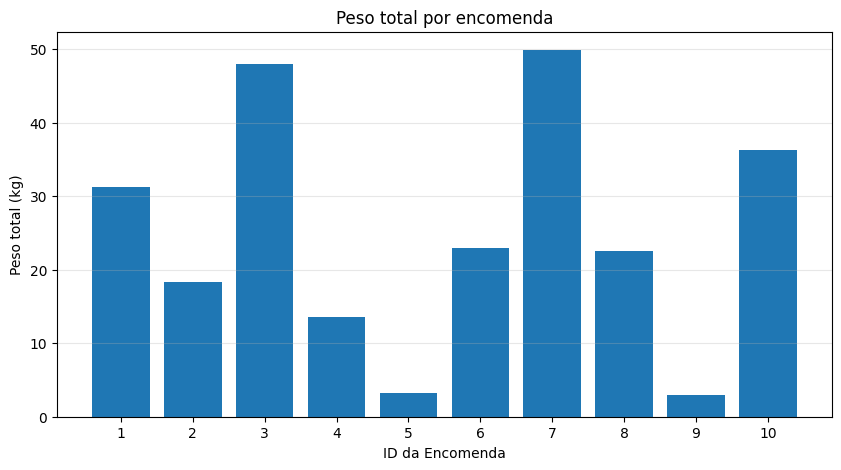

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    peso_encomendas["order_id"].astype(str),
    peso_encomendas["peso_total_kg"]
)

plt.title("Peso total por encomenda")
plt.xlabel("ID da Encomenda")
plt.ylabel("Peso total (kg)")
plt.grid(axis="y", alpha=0.3)

plt.show()


### 2.6.2. Análise dos Resultados dos Pesos

A representação gráfica dos pesos das encomendas permite identificar diferenças nas quantidades de produtos solicitadas pelos clientes.

A encomenda 7 apresenta o maior peso total, aproximadamente 50 kg, seguida da encomenda 3, com cerca de 48 kg. Por outro lado, as encomendas 5 e 9 apresentam os menores pesos, próximos de 3 kg.

Comparando estes resultados com as capacidades dos veículos disponíveis, verifica-se que os pesos individuais das encomendas são bastante inferiores aos limites de carga.

Assim, a capacidade dos veículos não parece constituir uma restrição particularmente exigente para este conjunto de dados. Contudo, durante a construção das rotas será necessário considerar a carga acumulada após cada recolha e entrega, garantindo que a capacidade máxima nunca é ultrapassada.

### 2.7. Análise das Localizações e Distâncias

Nesta etapa, pretende-se analisar as localizações geográficas presentes no dataset e a matriz de distâncias e tempos de deslocação.

O objetivo é compreender a distribuição espacial dos pontos de recolha e entrega e identificar as informações que serão utilizadas pelos algoritmos de procura para construir e otimizar as rotas.

In [ ]:

# Visualizar os pontos utilizados nas rotas
print("Tabela de localizações:")
display(dados["locations"])

# Visualizar as localidades
print("\nTabela de localidades:")
display(dados["localities"].head(10))

# Visualizar a matriz de distâncias
print("\nMatriz de distâncias:")
display(dados["distance_matrix"].head(10))

# Mostrar os nomes das colunas
for nome in ["locations", "localities", "distance_matrix"]:
    print(f"\nColunas de {nome}:")
    print(dados[nome].columns.tolist())


Tabela de localizações:


,location_id,location_type,ref_id,name,municipality,latitude,longitude
0,1,producer,1,Hortas Valente,Fafe,41.463574,-8.159840
1,2,producer,2,Quinta Leite,Vieira do Minho,41.627980,-8.166483
2,3,producer,3,Quinta Morais,Guimaraes,41.464457,-8.297740
3,4,producer,4,Pomar Carvalho,Povoa de Varzim,41.398757,-8.765766
4,5,producer,5,Pomar Antunes,Fafe,41.463574,-8.159840
5,6,collection_center,1,Centro de Recolha 1,Terras de Bouro,41.716185,-8.340221
6,7,delivery_location,1,Mercado Municipal 1,Esposende,41.561427,-8.763803
7,8,delivery_location,2,Casa 2,Vila Verde,41.632450,-8.433260
8,9,delivery_location,3,Casa 3,Braga,41.564989,-8.435147
9,10,delivery_location,4,Casa 4,Vizela,41.399802,-8.274785



Tabela de localidades:


,locality_id,name,municipality,district,latitude,longitude
0,1,Se,Braga,Braga,41.533518,-8.405528
1,2,Maximinos,Braga,Braga,41.564989,-8.435147
2,3,Real,Braga,Braga,41.551572,-8.425425
3,4,Nogueiro,Braga,Braga,41.559380,-8.408464
4,5,Dume,Braga,Braga,41.531493,-8.446483
5,6,Barcelos,Barcelos,Braga,41.555588,-8.618462
6,7,Barcelinhos,Barcelos,Braga,41.551914,-8.639995
7,8,Abade de Neiva,Barcelos,Braga,41.536069,-8.604023
8,9,Arcozelo,Barcelos,Braga,41.525238,-8.592836
9,10,Oliveira do Castelo,Guimaraes,Braga,41.462571,-8.315271



Matriz de distâncias:


,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
0,1,producer,2,producer,23.78,31.7
1,1,producer,3,producer,14.94,19.9
2,1,producer,4,producer,66.33,88.4
3,1,producer,5,producer,0.00,0.0
4,1,producer,6,collection_center,41.40,55.2
5,1,producer,7,delivery_location,66.89,89.2
6,1,producer,8,delivery_location,38.35,51.1
7,1,producer,9,delivery_location,33.21,44.3
8,1,producer,10,delivery_location,15.50,20.7
9,1,producer,11,delivery_location,33.42,44.6



Colunas de locations:
['location_id', 'location_type', 'ref_id', 'name', 'municipality', 'latitude', 'longitude']

Colunas de localities:
['locality_id', 'name', 'municipality', 'district', 'latitude', 'longitude']

Colunas de distance_matrix:
['origin_location_id', 'origin_type', 'destination_location_id', 'destination_type', 'distance_km', 'duration_min']


### 2.7.1. Resultados da Análise das Localizações

A análise do ficheiro `locations.csv` permitiu identificar 12 pontos geográficos relevantes para o planeamento das rotas, distribuídos por 5 produtores, 1 centro de recolha e 6 locais de entrega.

A tabela `distance_matrix.csv` contém 132 ligações entre pares de localizações distintas, incluindo as respetivas distâncias em quilómetros e tempos de deslocação em minutos.

Verificou-se que os produtores Hortas Valente e Pomar Antunes apresentam as mesmas coordenadas geográficas, resultando numa distância de 0 km entre ambos.

A matriz de distâncias constitui uma componente fundamental do problema, uma vez que permite calcular o custo das rotas e estimar os tempos de deslocação necessários para respeitar as janelas temporais das encomendas.

### 2.7.2. Visualização Geográfica das Localizações

Para compreender a distribuição espacial dos pontos relevantes para o problema, foi criado um mapa interativo utilizando a biblioteca Folium.

O mapa representa os produtores, o centro de recolha e os locais de entrega, permitindo visualizar a sua localização geográfica e a distribuição territorial dos pontos que serão considerados no planeamento das rotas.

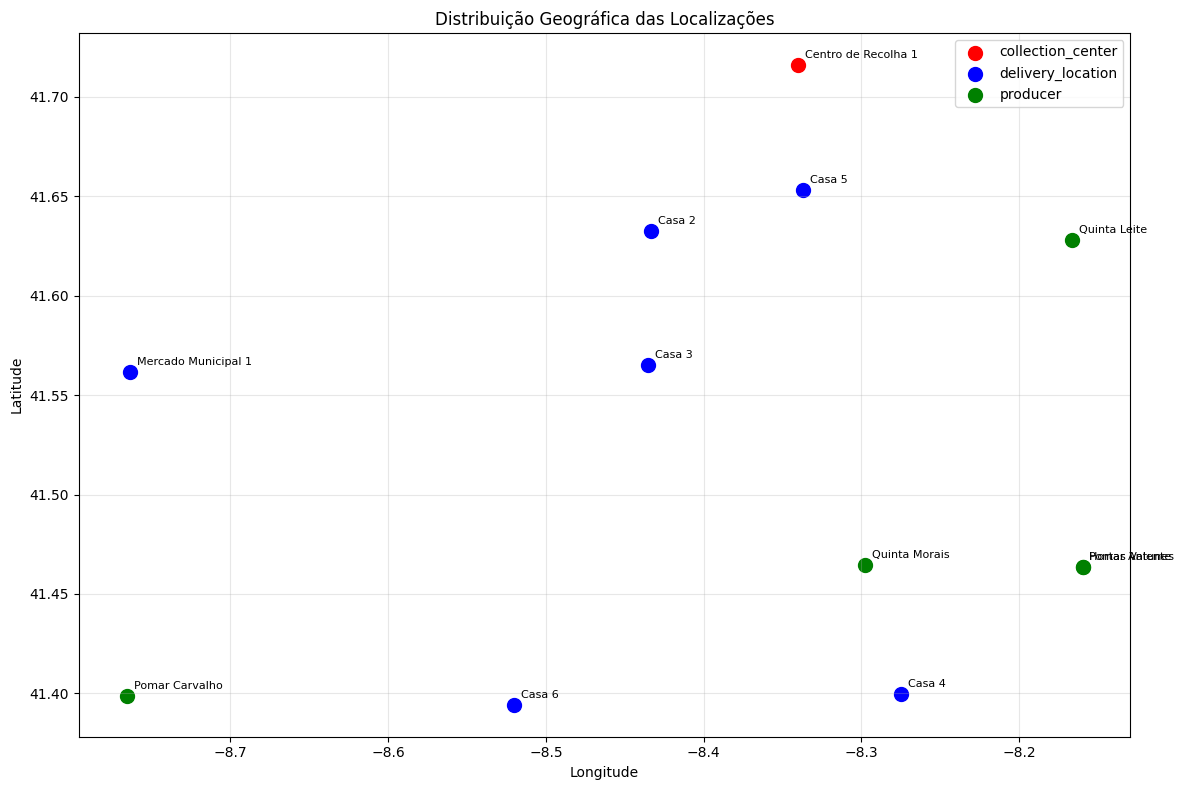

In [ ]:

import matplotlib.pyplot as plt

# Obter os dados das localizações
locais = dados["locations"]

# Definir cores para cada tipo
cores = {
    "producer": "green",
    "collection_center": "red",
    "delivery_location": "blue"
}

plt.figure(figsize=(12, 8))

# Representar os pontos geográficos
for tipo, grupo in locais.groupby("location_type"):
    plt.scatter(
        grupo["longitude"],
        grupo["latitude"],
        color=cores[tipo],
        label=tipo,
        s=100
    )

    # Identificar cada localização
    for _, local in grupo.iterrows():
        plt.annotate(
            local["name"],
            (local["longitude"], local["latitude"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.title("Distribuição Geográfica das Localizações")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


### 2.7.2. Visualização Geográfica das Localizações

Para analisar a distribuição geográfica dos pontos relevantes para o problema, foi criada uma representação gráfica utilizando a biblioteca Matplotlib.

O gráfico apresenta os produtores, o centro de recolha e os locais de entrega, identificados por diferentes cores.

Esta representação permite observar a distribuição espacial dos pontos e compreender as distâncias relativas entre as diferentes localizações, contribuindo para a posterior implementação dos algoritmos de otimização de rotas.
A análise da distribuição geográfica permite verificar que os produtores e os locais de entrega se encontram dispersos por diferentes municípios da região.

O centro de recolha situa-se em Terras de Bouro, enquanto os restantes pontos estão distribuídos por municípios como Braga, Fafe, Guimarães, Esposende e Póvoa de Varzim.

Verifica-se também que dois produtores, Hortas Valente e Pomar Antunes, apresentam coordenadas geográficas idênticas, pelo que os seus marcadores se encontram sobrepostos.

Esta dispersão geográfica reforça a importância da utilização de algoritmos de procura e otimização, capazes de encontrar percursos eficientes, considerando as distâncias, os tempos de deslocação e as restrições temporais das encomendas.

### 2.8. Verificação da Integridade Referencial

Nesta etapa, pretende-se verificar a consistência das relações entre as diferentes tabelas do dataset.

A análise permite identificar possíveis referências inválidas, como encomendas associadas a clientes inexistentes ou artigos associados a produtos que não estão registados.

Esta validação é importante para garantir que os dados podem ser utilizados de forma consistente na modelação e resolução do problema.

In [ ]:

# Verificar as relações entre as tabelas
relacoes = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("orders", "delivery_location_id",
     "delivery_locations", "delivery_location_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("products", "producer_id", "producers", "producer_id"),
    ("vehicles", "center_id",
     "collection_centers", "center_id")
]

print("Verificação da integridade referencial:\n")

for tabela, coluna, tabela_ref, coluna_ref in relacoes:

    invalidos = ~dados[tabela][coluna].isin(
        dados[tabela_ref][coluna_ref]
    )

    total = invalidos.sum()

    print(
        f"{tabela}.{coluna} -> "
        f"{tabela_ref}.{coluna_ref}: "
        f"{total} referências inválidas"
    )


Verificação da integridade referencial:

orders.customer_id -> customers.customer_id: 0 referências inválidas
orders.delivery_location_id -> delivery_locations.delivery_location_id: 0 referências inválidas
order_items.order_id -> orders.order_id: 0 referências inválidas
order_items.product_id -> products.product_id: 0 referências inválidas
products.producer_id -> producers.producer_id: 0 referências inválidas
vehicles.center_id -> collection_centers.center_id: 0 referências inválidas


### 2.9. Validação da Matriz de Distâncias

Nesta etapa, será realizada a análise da matriz de distâncias e tempos de deslocação entre as diferentes localizações.

O objetivo é verificar a consistência dos dados, identificar possíveis valores inválidos e confirmar que existem ligações entre todos os pares de localizações distintas.

Esta informação será fundamental para o cálculo dos custos das rotas e para a implementação dos algoritmos de procura informada.

In [ ]:

# Obter a matriz de distâncias
matriz = dados["distance_matrix"].copy()

# Número de localizações
n_locais = len(dados["locations"])

# Número esperado de ligações
ligacoes_esperadas = n_locais * (n_locais - 1)

print("Número de localizações:", n_locais)
print("Ligações esperadas:", ligacoes_esperadas)
print("Ligações existentes:", len(matriz))

# Verificar distâncias negativas
distancias_negativas = (matriz["distance_km"] < 0).sum()

# Verificar tempos negativos
tempos_negativos = (matriz["duration_min"] < 0).sum()

# Verificar valores em falta
valores_falta = matriz.isnull().sum().sum()

print("\nDistâncias negativas:", distancias_negativas)
print("Tempos negativos:", tempos_negativos)
print("Valores em falta:", valores_falta)

# Estatísticas das distâncias
print("\nEstatísticas das distâncias:")
display(matriz[["distance_km", "duration_min"]].describe())


Número de localizações: 12
Ligações esperadas: 132
Ligações existentes: 132

Distâncias negativas: 0
Tempos negativos: 0
Valores em falta: 0

Estatísticas das distâncias:


,distance_km,duration_min
count,132.000000,132.000000
mean,35.724848,47.633333
std,16.799530,22.396819
min,0.000000,0.000000
25%,23.780000,31.700000
50%,35.280000,47.050000
75%,48.000000,64.000000
max,72.840000,97.100000


In [ ]:

from itertools import permutations

# Identificadores das localizações
ids = set(dados["locations"]["location_id"])

# Todos os pares ordenados esperados
pares_esperados = set(permutations(ids, 2))

# Pares existentes na matriz
pares_existentes = list(zip(
    matriz["origin_location_id"],
    matriz["destination_location_id"]
))

pares_unicos = set(pares_existentes)

# Verificações
pares_falta = pares_esperados - pares_unicos
pares_duplicados = len(pares_existentes) - len(pares_unicos)

print("Pares em falta:", len(pares_falta))
print("Pares duplicados:", pares_duplicados)

# Verificar simetria
inverso = matriz.merge(
    matriz,
    left_on=["origin_location_id",
             "destination_location_id"],
    right_on=["destination_location_id",
              "origin_location_id"],
    suffixes=("_ida", "_volta")
)

diferencas = inverso[
    (abs(inverso["distance_km_ida"] -
         inverso["distance_km_volta"]) > 0.01) |
    (abs(inverso["duration_min_ida"] -
         inverso["duration_min_volta"]) > 0.01)
]

print("Ligações com diferenças entre ida e volta:",
      len(diferencas))

# Verificar ligações do ponto para si próprio
auto_ligacoes = matriz[
    matriz["origin_location_id"] ==
    matriz["destination_location_id"]
]

print("Auto-ligações:", len(auto_ligacoes))


Pares em falta: 0
Pares duplicados: 0
Ligações com diferenças entre ida e volta: 0
Auto-ligações: 0


### 2.9.1. Resultados da Validação da Matriz de Distâncias

A análise da matriz de distâncias permitiu confirmar a existência de 132 ligações entre as 12 localizações, correspondendo ao número esperado de pares ordenados de pontos distintos.

Não foram identificados pares em falta, ligações duplicadas, distâncias negativas, tempos de deslocação negativos ou valores em falta.

Verificou-se também que a matriz é simétrica, apresentando os mesmos valores de distância e duração para ambos os sentidos de cada ligação.

A distância média entre localizações é de aproximadamente 35,72 km, enquanto o tempo médio de deslocação é de 47,63 minutos. A distância máxima registada é de 72,84 km, correspondendo a um tempo de 97,10 minutos.

A existência de distâncias nulas entre localizações distintas deve-se à presença de produtores com coordenadas geográficas idênticas.

Conclui-se que a matriz apresenta uma estrutura consistente e adequada para ser utilizada no cálculo dos custos das rotas e na implementação dos algoritmos de procura.

Importa salientar que os valores representam aproximações sintéticas das distâncias e dos tempos reais de deslocação.

## 3. Conclusão da Análise Exploratória dos Dados

A Análise Exploratória dos Dados permitiu compreender a estrutura e as principais características do dataset disponibilizado para o projeto.

Foram identificados 5 produtores, 8 clientes, 10 encomendas, 23 artigos encomendados, 2 veículos, 1 centro de recolha e 6 locais de entrega.

A análise das encomendas permitiu identificar as janelas temporais de disponibilidade e entrega dos produtos. Embora todos os intervalos temporais apresentem uma ordenação válida, foram identificados 12 artigos cuja disponibilidade termina antes da criação da respetiva encomenda. Estas situações poderão tornar a recolha inviável caso seja obrigatório realizá-la após o pedido.

A análise dos pesos permitiu comparar as necessidades de transporte com as capacidades dos veículos. Verificou-se que os pesos individuais das encomendas são bastante inferiores aos limites de carga disponíveis.

A representação geográfica permitiu visualizar a distribuição dos produtores, do centro de recolha e dos locais de entrega, demonstrando a importância do planeamento eficiente das rotas.

A validação das relações entre tabelas e da matriz de distâncias permite ainda avaliar a consistência dos dados que serão utilizados nas fases seguintes.

Conclui-se que a análise realizada constitui uma base importante para a modelação do problema e para a implementação dos algoritmos Greedy Best-First Search, A*, Hill Climbing e CSP, que serão utilizados na procura de soluções eficientes e no cumprimento das restrições definidas.